# **EXPLAINABLE CREDIT RISK ASSESSMENT**

In [1]:
#Importing Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
#Loading the dataset
df = pd.read_csv('/content/credit_risk_dataset (2).csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


# **EDA - EXPLORATORY DATA ANALYSIS**

In [3]:
#BASIC INFORMATION

df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [4]:
#Missing Values
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


<Axes: xlabel='loan_status', ylabel='count'>

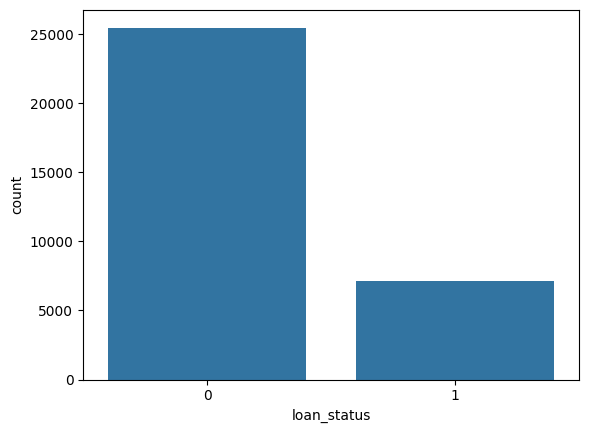

In [5]:
#TARGET BALANCE -  BALANCED OR IMBALANCED DATA

df['loan_status'].unique()
df['loan_status'].value_counts()

sns.countplot(x='loan_status',data=df)

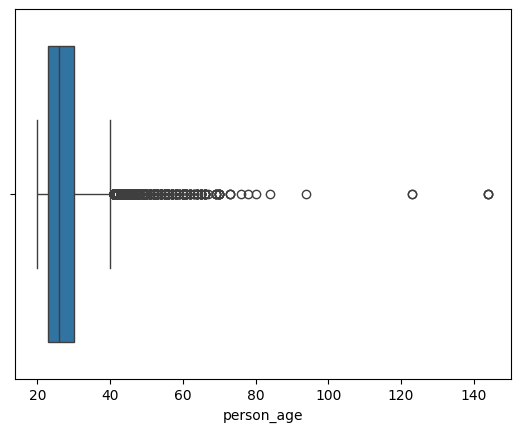

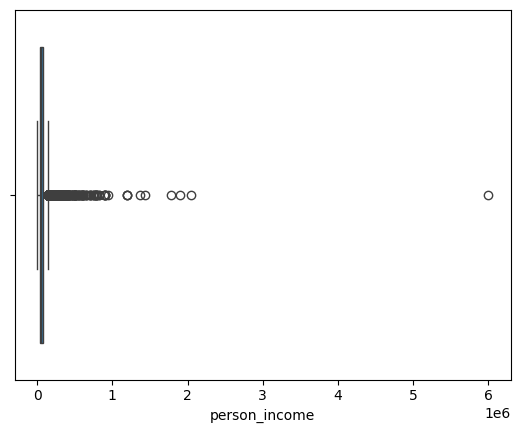

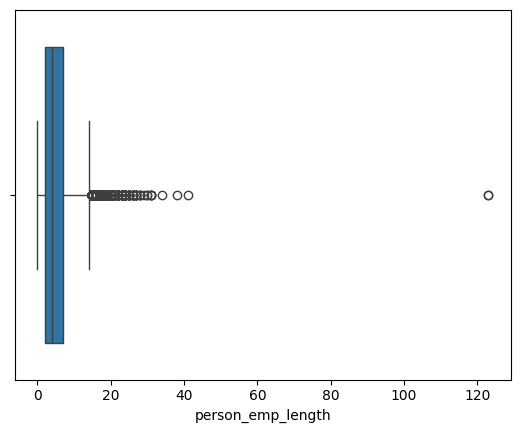

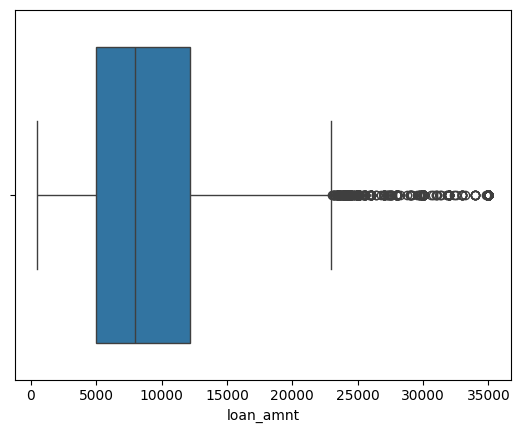

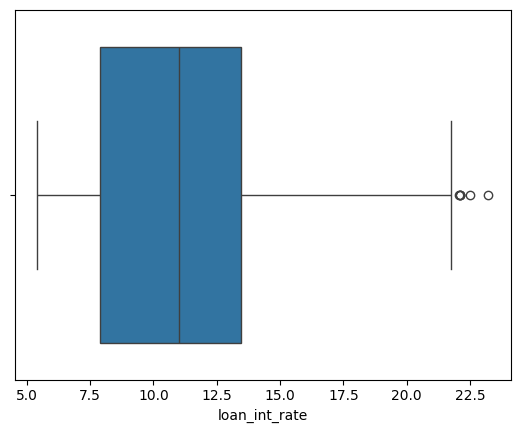

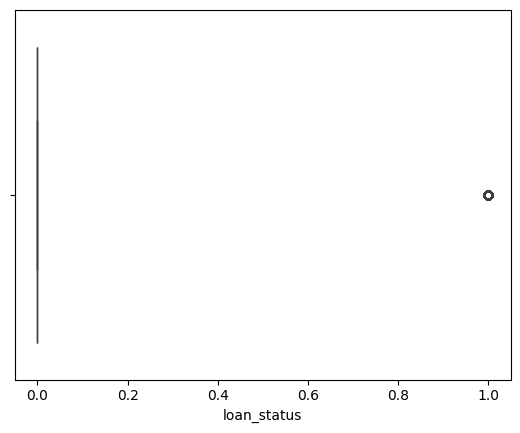

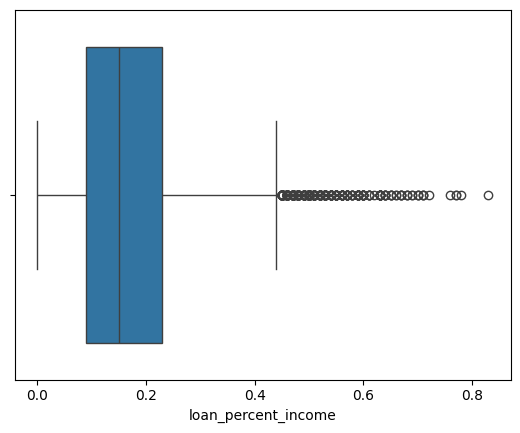

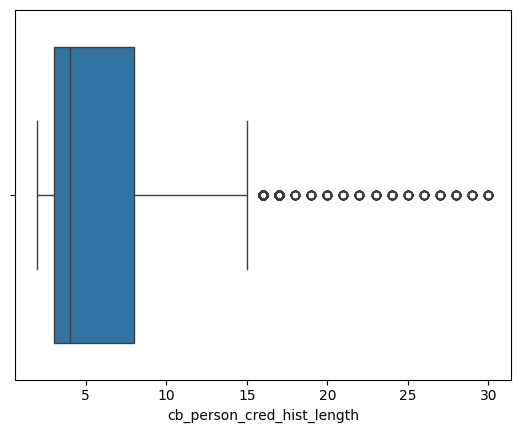

In [6]:
#OUTLIER CHECK

numerical_cols = df.select_dtypes(include=np.number)

for i in numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()




In [7]:
(df['person_age']>100).sum()

np.int64(5)

In [8]:
(df['person_emp_length']>60).sum()

np.int64(2)

<Axes: >

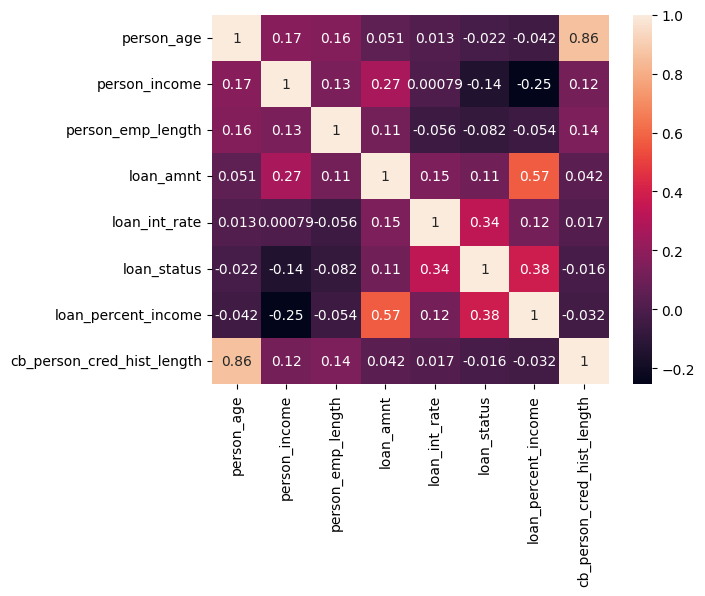

In [9]:
#Correlation Check

sns.heatmap(df.corr(numeric_only = True),annot=True)

# **DATA VALIDATION & OUTLIER HANDLING**




In [10]:
#Creation of copy of dataset
df_copy = df.copy()
print(df_copy.shape[0])

#Remove duplicates rows
df_copy.drop_duplicates(inplace=True)

print(df_copy.shape[0])

#Remove ages below 18 and above 100
df_copy = df_copy[df_copy['person_age']>=18]
df_copy = df_copy[df_copy['person_age']<=100]
#Remove employment length greater than age or extreme outliers (>60)
df_copy = df_copy[df_copy['person_emp_length']<=df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length']<=60]
#Remove less than or equal to 0 loan amounts
df_copy = df_copy[df_copy['loan_amnt']>0]



32581
32416


### **FEATURES,TARGET & TRAIN-TEST SPLIT**

In [11]:
X = df_copy.drop('loan_status',axis=1)
y = df_copy['loan_status']

In [12]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


In [13]:
numeric_cols = ['person_age','person_income','person_emp_length','loan_amnt','loan_int_rate','loan_percent_income','cb_person_cred_hist_length']
categorical_cols = ['person_home_ownership','loan_intent','loan_grade','cb_person_default_on_file']

# **Handle Class Imbalance**

In [14]:
y_train.value_counts()

neg,pos = np.bincount(y_train)
scale_weights = neg/pos

# **PIPELINE & COLUMN TRANSFORMER**

In [15]:
from sklearn import pipeline
#Preprocessing Logistic Regression
#impute + SCALE Numeric, impute + One-Hot Encoding

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers = [
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
            ('scale',StandardScaler())
        ]),numeric_cols),
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='constant',fill_value="Missing")),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),categorical_cols)
    ]
)


In [16]:
# Preprocessing for XGBOOST
# XGBoost: Impute numeric only (NO SCALING), impute+one-hot encoding
preprocessor_xg = ColumnTransformer(
    transformers = [
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
        ]),numeric_cols),
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='constant',fill_value="Missing")),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),categorical_cols)
    ]
)



# **Evaluation Helper Function**

In [17]:
#We have to evaluate Logistic Model and XGBoost model on the basis of their metrics

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, precision_recall_curve
def evaluate_model(model_name, model, X_test, y_test, threshold=None):
  y_pred_prob = model.predict_proba(X_test)[:,1]

  if threshold is not None:
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(X_test)

  #Metrics
  accuracy     = accuracy_score(y_test, y_pred)    #Overall model's preformance
  precision    = precision_score(y_test, y_pred)   #When the model says 1, how oftenly is it actually 1.
  recall       = recall_score(y_test, y_pred)      #of the actual 1 how many did the model catches
  f1           = f1_score(y_test, y_pred)          #Harmonic mean of precision and recall

  conf_matrix   = confusion_matrix(y_test, y_pred)
  class_report  = classification_report(y_test, y_pred)


  print(f"{model_name} Metrics:")
  if threshold is not None: # Only print threshold if provided
    print(f"Used Threshold : {threshold:.2f}")
  print(f"Accuracy : {accuracy:.2f}")
  print(f"Precision : {precision:.2f}")
  print(f"Recall : {recall:.2f}")
  print(f"F1 : {f1:.2f}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)


  #Plotting confusion matrix
  sns.heatmap(conf_matrix, annot=True, fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.ylabel("Actual Values")
  plt.xlabel("Predicted Values")
  plt.show()


  #Plotting ROC-AUC curve
  precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()

# **Stratified Cross-Validation**

In [18]:
from numpy.random import RandomState
from sklearn.model_selection import StratifiedKFold,cross_validate
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring = {'roc_auc':'roc_auc','accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1'}


In [19]:
#Logistic Regression Model

from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42))
])

lr_cv_pipeline


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [20]:
#XGboost Model

from xgboost import XGBClassifier
xg_cv_pipeline = Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(n_estimators=300,max_depth=5,learning_rate=0.1,
                                random_state=42,scale_pos_weight=scale_weights))
])


In [21]:
#CROSS VALIDATION - SCORES ALSO
for cv_name, pipe in [("Logistic Regression",lr_cv_pipeline),("XGboost",xg_cv_pipeline)]:
  cv_results=cross_validate(pipe,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
  print(cv_name)
  print(f"ROC AUC: {cv_results['test_roc_auc'].mean():.3f}")
  print(f"Accuracy: {cv_results['test_accuracy'].mean():.3f}")
  print(f"Precision: {cv_results['test_precision'].mean():.3f}")
  print(f"Recall: {cv_results['test_recall'].mean():.3f}")

Logistic Regression
ROC AUC: 0.871
Accuracy: 0.812
Precision: 0.545
Recall: 0.778
XGboost
ROC AUC: 0.947
Accuracy: 0.918
Precision: 0.819
Recall: 0.796


# BASELINE MODEL - LOGISTIC REGRESSION

In [22]:
baseline_model = Pipeline([
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(class_weight="balanced"))
])

baseline_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

# XGBOOST MODEL

In [23]:
xg_model = Pipeline(
    [
        ('preprocessor',preprocessor_xg),
        ('classifier',XGBClassifier(learning_rate=0.1,
                                    random_state=42,scale_pos_weight=scale_weights))
    ]
)

xg_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [24]:
#Evaluate the Logistic Model

Baseline Logistic Model Metrics:
Accuracy : 0.82
Precision : 0.56
Recall : 0.79
F1 : 0.65

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



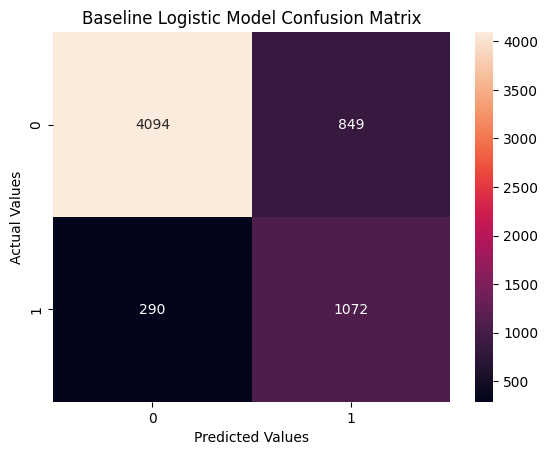

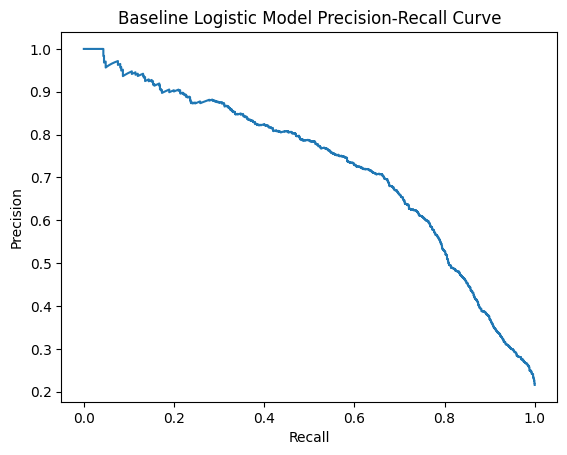

In [25]:
evaluate_model("Baseline Logistic Model", baseline_model ,X_test, y_test)


XGBoost Model Metrics:
Accuracy : 0.92
Precision : 0.82
Recall : 0.79
F1 : 0.81

XGBoost Model Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



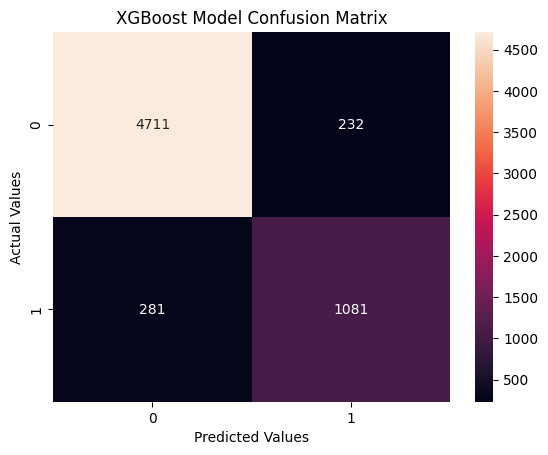

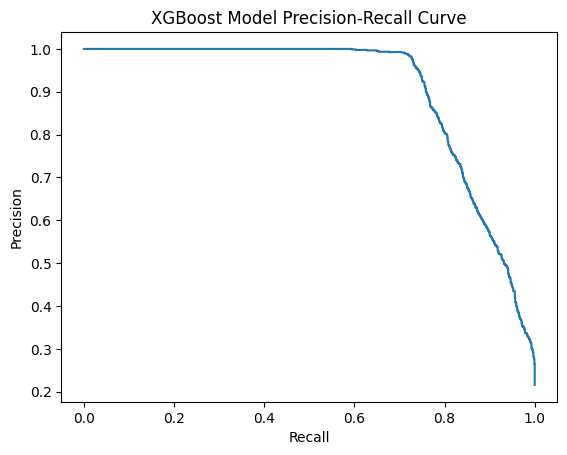

In [26]:
# Evaluate XGBoost Model
evaluate_model("XGBoost Model", xg_model, X_test, y_test)



# HYPERPARAMETER TUNING

In [27]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" :uniform(0.6,0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}

In [28]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7ccadc1a7ed0>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7ccadd962120>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7ccadc1a7b10>},
                   scoring='average_precision', verbose=1)

In [29]:
print(f"Score after performing Tunning {random_search.best_score_:.2f}")

Score after performing Tunning 0.90


In [30]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.9187715475995544),
 'classifier__gamma': np.float64(1.0051062350917739),
 'classifier__learning_rate': np.float64(0.10524993755596278),
 'classifier__max_depth': 6,
 'classifier__min_child_weight': 5,
 'classifier__n_estimators': 375,
 'classifier__subsample': np.float64(0.9313459349894896)}

# Compare Both Models Side by Side

Baseline Logistic Model Metrics:
Accuracy : 0.82
Precision : 0.56
Recall : 0.79
F1 : 0.65

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



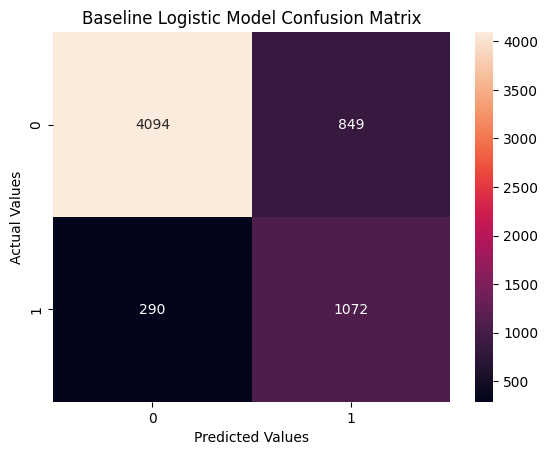

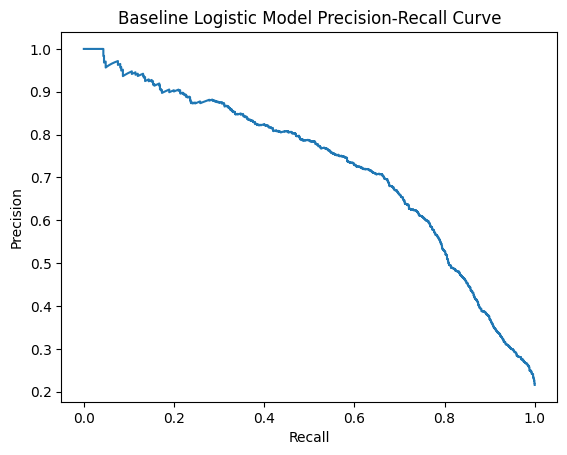

In [31]:
evaluate_model("Baseline Logistic Model", baseline_model ,X_test, y_test)


XGBoost Model Metrics:
Accuracy : 0.93
Precision : 0.84
Recall : 0.81
F1 : 0.82

XGBoost Model Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      4943
           1       0.84      0.81      0.82      1362

    accuracy                           0.93      6305
   macro avg       0.89      0.88      0.89      6305
weighted avg       0.92      0.93      0.92      6305



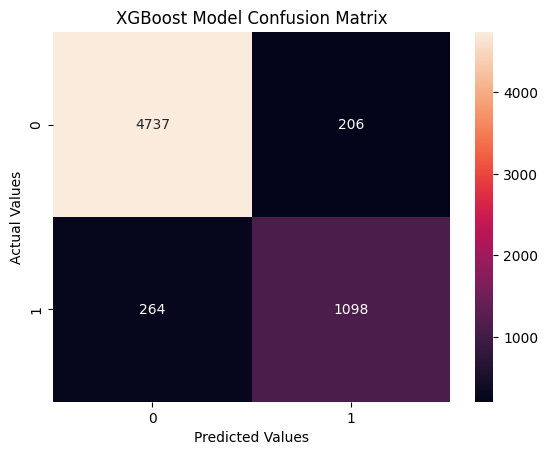

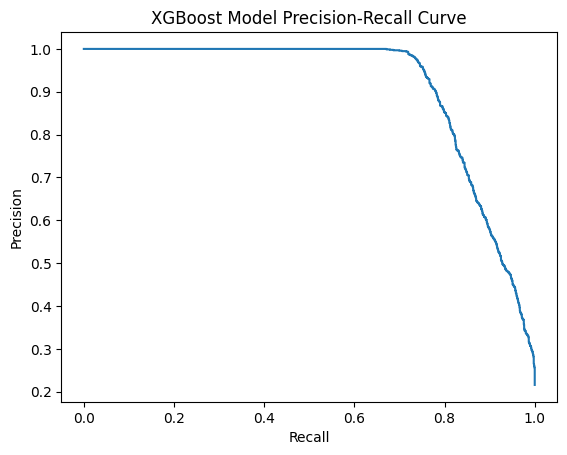

In [32]:
evaluate_model("XGBoost Model", random_search, X_test, y_test)

# Optimizing the Classification Threshold

# **Probability Calibration**

Sometimes a model's probability doesn't mean what it says.
For example, 30% risk should truly mean a 30% chance.
We check this with a calibration plot.
We fix it if the probabilities are off.




In [33]:
"""
Methods by which we can fix the poorly calibrated model.
1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.
2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibartion)
3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature
"""


'\nMethods by which we can fix the poorly calibrated model.\n1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.\n2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibartion)\n3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature\n'

In [34]:
#1 Calibrated XGBoost model
from sklearn.calibration import CalibratedClassifierCV,calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train,y_train)


CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.10524993755596278),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=5,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=375,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

Calibrated XGBoost Metrics:
Used Threshold : 0.75
Accuracy : 0.94
Precision : 0.98
Recall : 0.74
F1 : 0.84

Calibrated XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      4943
           1       0.98      0.74      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.96      0.87      0.90      6305
weighted avg       0.94      0.94      0.94      6305



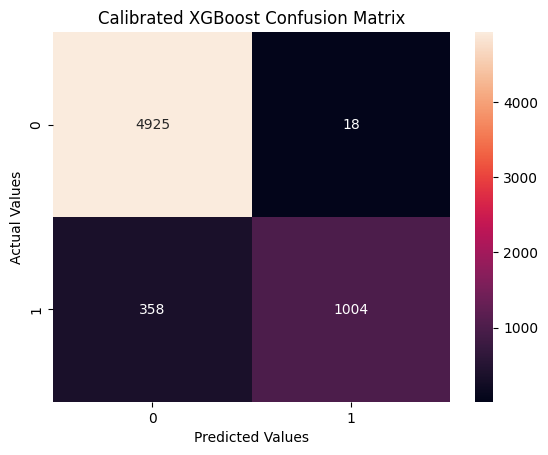

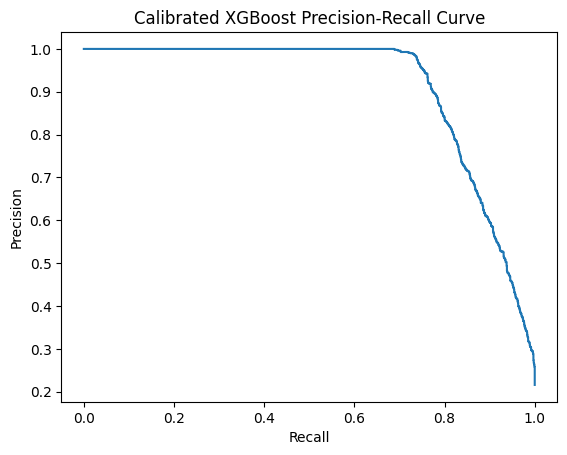

In [35]:
#Get the prob. of class 1 from the calibrated XGBoost model
prob = calibrated_model.predict_proba(X_test)[:, 1]

#For each threshold calculate Precision and Recall
precisions, recalls, thresholds = precision_recall_curve(y_test, prob)


#Calculate F1 score for each threshold
f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

#Get the threshold that produces the highest f1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

#Evaluate the calibrated XGBoost model using that threshold.
evaluate_model("Calibrated XGBoost", calibrated_model, X_test, y_test, best_threshold)


In [36]:
#2 Get Probabilities
uncalibrated = xg_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

In [37]:
# create calibration curves

actual_uncal,predicted_uncal = calibration_curve(y_test,uncalibrated,n_bins=10)
actual_cal,predicted_cal = calibration_curve(y_test,calibrated,n_bins=10)

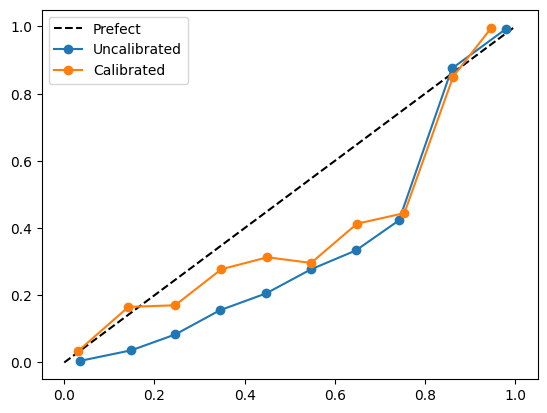

In [38]:
#PLOT

plt.plot([0,1], [0,1], 'k--', label="Prefect")
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label = "Uncalibrated"
)

plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label = "Calibrated"
)
plt.legend()

# **SHAP Interpretation - Global & Local**

In [39]:
#Install SHAP if not exists
!pip install shap
import shap

In [40]:
#2 Get the trained XGBoost model out of the tuned pipeline
xgb_classifier = best_model.named_steps['classifier']

#3 Transform X_test using the same preprocessing used for training.
X_test_transformed = best_model.named_steps['preprocessor'].transform(X_test)


#4 Get feature names after one-hot encoding, so plots are readable

feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

#5 Convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

#6 Create SHAP Explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

#7 Create SHAP values
shap_values = explainer.shap_values(X_test_df)


**Global Explanation**

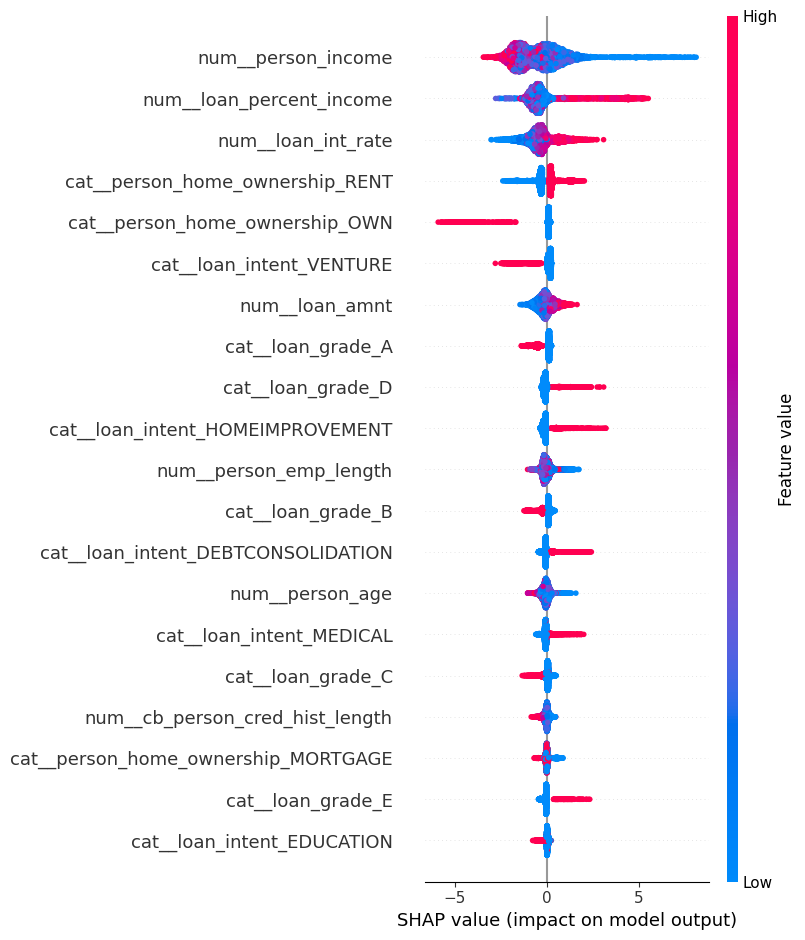

In [41]:
shap.summary_plot(shap_values,X_test_df)

**Local Explanation**

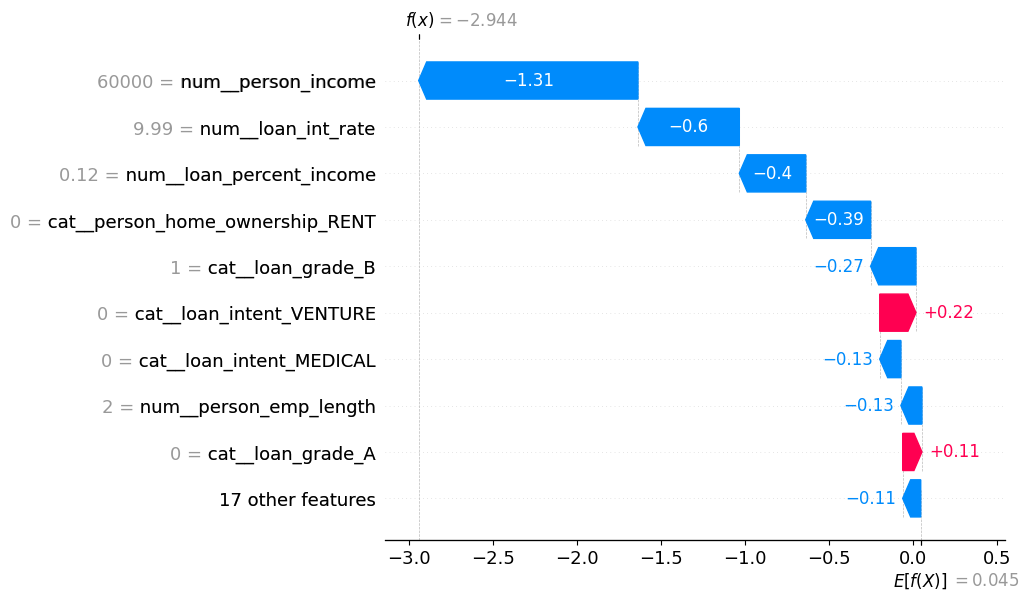

In [42]:
#Pick one row to explain , e.g the 5th applicant in the test set
row_index = 5

#Draw a waterfall plot showing how each feature pushed the prediction up or down
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[row_index],
        base_values=explainer.expected_value,
        data=X_test_df.iloc[row_index],
        feature_names=feature_names
    )
)

# **Analyzing False Positives & False Negatives**

In [43]:
#Get predictions from the best performing XGBoost model on the test set

y_pred = random_search.predict(X_test)

In [44]:
#Create a dataframe to compare the actual and predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [45]:
#Identify false Positive : Model predicted 1 , but the actual was 0
false_positives = result_df[(result_df['predicted'] == 1) & (result_df['actual'] == 0)]

#Identify false Negative : Model predicted 0 , but the actual was 1
false_negatives = result_df[(result_df['predicted'] == 0) & (result_df['actual'] == 1)]


In [46]:
print(f"False Positives : {len(false_positives)}")
print(f"False Negatives : {len(false_negatives)}")

False Positives : 206
False Negatives : 264


# **SAVE THE FINAL MODEL**

In [47]:
import joblib

joblib.dump(calibrated_model,"credit_risk_model.pkl")

['credit_risk_model.pkl']

In [48]:
joblib.dump(best_threshold,"best_threshold.pkl")

['best_threshold.pkl']